# 06seaice: observed sea ice for the page

PF9, step 7. Downloads the observed monthly sea ice concentration for our map window, every month from 1979 to the latest month, and turns it into ice pictures for the page and a table of ice area over the years.

Data: **NOAA/NSIDC Climate Data Record of Passive Microwave Sea Ice Concentration, Version 6** (G02202 v6, monthly, 25 km grid, satellite measurements). Served by the NOAA CoastWatch ERDDAP server (free, no login, no Copernicus).

1. **Download:** only a small box around our map, in pieces of ten years. Files already there are skipped. A few MB in total, usually a few minutes.
2. **Check:** reads the pieces, joins them and reports what came out (months, gaps, values).
3. **Regrid:** moves the 25 km satellite grid onto the page's map (local equal-area grid, 2 km cells), smoothly, and removes land.
4. **Outputs:** one ice picture per chosen month for the page (`docs/data/ice/ice_YYYYMM.png`), an index file with the monthly ice area for a chart (`docs/data/ice/ice_index.json`), a table (`data/nsidc_ice_monthly.csv`) and figures.

The 25 km grid is coarse: the ice edge on the page is smoothed, and narrow places (the strait itself is about 80 km wide, so 3 cells) and coasts are only roughly right. Values near the coast can be too high ("land spillover").

## Section 0. Settings

Lines marked `# <-` can be changed. `VISUAL:` settings only change the pictures, not the numbers.

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw" / "nsidc"
WEB_DIR = PROJECT_DIR / "docs" / "data"
ICE_DIR = WEB_DIR / "ice"
FIG_DIR = PROJECT_DIR / "figures"

ERDDAP_SERVERS = ["https://coastwatch.pfeg.noaa.gov/erddap", "https://polarwatch.noaa.gov/erddap"]  # <- tried in this order
DATASET = "nsidcG02202v6nhmday"  # <- NSIDC CDR v6, Northern Hemisphere, monthly
VARIABLE = "cdr_seaice_conc_monthly"  # <- ice concentration, 0 to 1
SOURCE_CRS = "+proj=stere +lat_0=90 +lat_ts=70 +lon_0=-45 +k=1 +x_0=0 +y_0=0 +a=6378273 +b=6356889.449 +units=m +no_defs"  # <- EPSG:3411, from the dataset
SOURCE_CELL_M = 25000  # <- source grid cell size
FIRST_YEAR = 1979  # <- first full year of the record
PIECE_YEARS = 10  # <- years per download piece
PAD_KM = 75  # <- extra margin around our map in the download box
TIMEOUT_S = 300  # <- give up on one request after this many seconds
RETRIES = 3  # <- tries per request and server

IMG_RES_M = 2000  # <- cell size of the page pictures and of the area numbers
IMAGE_YEARS = "all"  # <- years to make page pictures for: "all", or a list such as [1995, 2000, 2005]
IMAGE_MONTHS = [2, 5, 8, 11]  # <- months to make page pictures for (the page's months)
EDGE = 0.15  # <- ice edge: less than 15% ice counts as open water (the usual definition of ice extent)
ICE_RGB_THICK = [248, 251, 253]  # <- VISUAL: ice colour at 100% ice (solid white)
ICE_RGB_THIN = [176, 194, 206]  # <- VISUAL: ice colour at the ice edge (thin, broken ice: grey-blue)
ALPHA_LOW = 215  # <- VISUAL: opacity (0 to 255) at the ice edge
ALPHA_HIGH = 255  # <- VISUAL: opacity at 100% ice

STRAIT_LAT = 65.75  # <- strait centre (between the Diomedes)
STRAIT_LON = -169.0  # <- degrees, west negative
NEAR_STRAIT_KM = 150  # <- radius for the "near the strait" ice numbers
MAP_YEAR = 2000  # <- year shown in the map figure of Section 5

## Section 1. Libraries, the page's map and the download box

In [2]:
import time
import json
import datetime as dt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from PIL import Image
from pyproj import Transformer
from scipy import ndimage
import matplotlib.pyplot as plt

RAW_DIR.mkdir(parents=True, exist_ok=True)
ICE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

meta = json.loads((WEB_DIR / "bering_meta.json").read_text(encoding="utf-8"))
L, B, R, T = meta["local_bounds_m"]
local_to_src = Transformer.from_crs(meta["local_crs"], SOURCE_CRS, always_xy=True)
ll_to_local = Transformer.from_crs("EPSG:4326", meta["local_crs"], always_xy=True)

# Page grid: cell centres, rows from north to south (like the page pictures)
nx = int(round((R - L) / IMG_RES_M))
ny = int(round((T - B) / IMG_RES_M))
gx = L + (np.arange(nx) + 0.5) * (R - L) / nx
gy = T - (np.arange(ny) + 0.5) * (T - B) / ny
GX, GY = np.meshgrid(gx, gy)
SX, SY = local_to_src.transform(GX, GY)
cell_km2 = ((R - L) / nx) * ((T - B) / ny) / 1e6  # equal-area grid, so every cell has the same area

# Water on the page (from the page's height picture), so land never gets ice
hp = np.asarray(Image.open(WEB_DIR / meta["height_png"]).convert("RGB")).astype(np.int64)
baked = (hp[..., 0] * 65536 + hp[..., 1] * 256 + hp[..., 2]) * 0.1 - 100000
h_rows, h_cols = baked.shape
col = np.clip(((GX - L) / (R - L) * (h_cols - 1)).round().astype(int), 0, h_cols - 1)
row = np.clip(((T - GY) / (T - B) * (h_rows - 1)).round().astype(int), 0, h_rows - 1)
water = baked[row, col] < 0

sx0, sy0 = ll_to_local.transform(STRAIT_LON, STRAIT_LAT)
near = water & (np.hypot(GX - sx0, GY - sy0) <= NEAR_STRAIT_KM * 1000)

# Download box in the source grid: the edges of our map, plus a margin, snapped to cell centres
edge = np.linspace(0, 1, 200)
ex = np.concatenate([L + (R - L) * edge, np.full(200, R), R - (R - L) * edge, np.full(200, L)])
ey = np.concatenate([np.full(200, B), B + (T - B) * edge, np.full(200, T), T - (T - B) * edge])
bx, by = local_to_src.transform(ex, ey)
pad = PAD_KM * 1000
half = SOURCE_CELL_M / 2


def snap(v, down):
    k = np.floor((v - half) / SOURCE_CELL_M) if down else np.ceil((v - half) / SOURCE_CELL_M)
    return float(k * SOURCE_CELL_M + half)


BOX = {"xmin": snap(bx.min() - pad, True), "xmax": snap(bx.max() + pad, False), "ymin": snap(by.min() - pad, True), "ymax": snap(by.max() + pad, False)}
box_cells = (round((BOX["xmax"] - BOX["xmin"]) / SOURCE_CELL_M) + 1, round((BOX["ymax"] - BOX["ymin"]) / SOURCE_CELL_M) + 1)
print("Page grid:", nx, "x", ny, "cells of", IMG_RES_M / 1000, "km;", int(water.sum()), "water cells; near the strait:", int(near.sum()))
print("Download box (EPSG:3411 m):", BOX)
print("Download box size:", box_cells[0], "x", box_cells[1], "source cells")

Page grid: 727 x 482 cells of 2.0 km; 164212 water cells; near the strait: 13274
Download box (EPSG:3411 m): {'xmin': -2837500.0, 'xmax': -1037500.0, 'ymin': 412500.0, 'ymax': 2337500.0}
Download box size: 73 x 78 source cells


## Section 2. Download

One file per piece of `PIECE_YEARS` years: `data/raw/nsidc/nsidc_v6_YYYY_YYYY.nc`. Existing files are skipped. The last piece ends at the latest month on the server; delete that file and run again to bring it up to date later.

The dataset's y axis runs from north to south, so the request asks for y from the top down.

In [3]:
def request_url(server, t0, t1):
    tq = f"[({t0}):1:({t1})]"
    yq = f"[({BOX['ymax']}):1:({BOX['ymin']})]"
    xq = f"[({BOX['xmin']}):1:({BOX['xmax']})]"
    return f"{server}/griddap/{DATASET}.nc?{VARIABLE}{tq}{yq}{xq}"


def fetch(t0, t1, dest):
    errors = []
    for server in ERDDAP_SERVERS:
        url = request_url(server, t0, t1)
        for attempt in range(1, RETRIES + 1):
            try:
                t_start = time.perf_counter()
                with requests.get(url, timeout=TIMEOUT_S, stream=True) as r:
                    if r.status_code != 200:
                        errors.append(f"{server} HTTP {r.status_code}: {r.text[:200]}")
                        if r.status_code in (400, 404):
                            break
                        time.sleep(5 * attempt)
                        continue
                    tmp = dest.with_suffix(".part")
                    with open(tmp, "wb") as f:
                        for chunk in r.iter_content(1 << 20):
                            f.write(chunk)
                    tmp.replace(dest)
                return time.perf_counter() - t_start, None
            except requests.RequestException as e:
                errors.append(f"{server}: {e}")
                time.sleep(5 * attempt)
    return None, " | ".join(errors[-3:])


this_year = dt.date.today().year
pieces = []
for a in range(FIRST_YEAR, this_year + 1, PIECE_YEARS):
    b = min(a + PIECE_YEARS - 1, this_year)
    pieces.append((a, b))
print("Example request:", request_url(ERDDAP_SERVERS[0], "1979-01-01T00:00:00Z", "1979-01-01T00:00:00Z"))

failed = []
for a, b in pieces:
    dest = RAW_DIR / f"nsidc_v6_{a}_{b}.nc"
    if dest.exists():
        print(f"{a} to {b}: already there ({dest.stat().st_size / 1e6:.2f} MB)")
        continue
    t1 = "last" if b == this_year else f"{b}-12-01T00:00:00Z"
    secs, err = fetch(f"{a}-01-01T00:00:00Z", t1, dest)
    if err:
        failed.append((a, b, err))
        print(f"{a} to {b}: FAILED: {err}")
    else:
        print(f"{a} to {b}: {dest.stat().st_size / 1e6:.2f} MB in {secs:.1f} s")
print("Failed pieces (run this cell again to retry):", [(a, b) for a, b, _ in failed])

Example request: https://coastwatch.pfeg.noaa.gov/erddap/griddap/nsidcG02202v6nhmday.nc?cdr_seaice_conc_monthly[(1979-01-01T00:00:00Z):1:(1979-01-01T00:00:00Z)][(2337500.0):1:(412500.0)][(-2837500.0):1:(-1037500.0)]
1979 to 1988: already there (2.75 MB)
1989 to 1998: already there (2.75 MB)
1999 to 2008: already there (2.75 MB)
2009 to 2018: already there (2.75 MB)
2019 to 2026: already there (2.15 MB)
Failed pieces (run this cell again to retry): []


## Section 3. Check what came out

In [4]:
files = sorted(RAW_DIR.glob("nsidc_v6_*.nc"))
assert files, "No files in data/raw/nsidc yet: run Section 2"
parts = []
for f in files:
    ds = xr.open_dataset(f, engine="scipy")
    parts.append(ds[[VARIABLE]].load())
    ds.close()
ice = xr.concat(parts, dim="time").sortby("time")
ice = ice.isel(time=~ice["time"].to_index().duplicated())
conc_all = ice[VARIABLE]
raw_vals = conc_all.values
flags = np.isfinite(raw_vals) & (raw_vals > 1)
conc_all = conc_all.where((conc_all >= 0) & (conc_all <= 1))  # land, coast and missing flags (above 1) become empty

times = ice["time"].to_index()
print("Files:", len(files), "using", round(sum(f.stat().st_size for f in files) / 1e6, 2), "MB")
print("Months:", len(times), "from", times[0].strftime("%Y-%m"), "to", times[-1].strftime("%Y-%m"))
print("Grid:", ice.sizes["x"], "x", ice.sizes["y"], "cells; x", float(ice.x.min()), "to", float(ice.x.max()), "; y", float(ice.y.min()), "to", float(ice.y.max()))
print("Flag values found (land, coast, missing):", sorted(set(np.round(raw_vals[flags], 2).tolist())))
all_months = pd.date_range(f"{FIRST_YEAR}-01-01", times[-1], freq="MS")
missing = [m.strftime("%Y-%m") for m in all_months if m not in times]
empty = [t.strftime("%Y-%m") for t, n in zip(times, np.isfinite(conc_all.values).sum(axis=(1, 2))) if n == 0]
print("Months missing from the files:", missing if missing else "none")
print("Months with no valid values:", empty if empty else "none")

Files: 5 using 13.14 MB
Months: 574 from 1979-01 to 2026-10
Grid: 73 x 78 cells; x -2837500.0 to -1037500.0 ; y 412500.0 to 2337500.0
Flag values found (land, coast, missing): []
Months missing from the files: none
Months with no valid values: ['1984-07', '1987-12', '1988-01']


## Section 4. Regrid onto the page's map, pictures and table

For each month: empty cells (land, coast) are first filled from the nearest sea cell so the coast is not eaten away, then the values are read off smoothly (bilinear) at the page grid's cell centres, and land is removed with the page's own coastline.

- **Ice area** = sum of (concentration x cell area) over water cells with at least `EDGE` ice.
- **Ice extent** = area of water cells with at least `EDGE` ice.

In [5]:
xs = ice["x"].values
ys = ice["y"].values
fcol = (SX - xs[0]) / (xs[1] - xs[0])
frow = (SY - ys[0]) / (ys[1] - ys[0])
outside = (fcol < 0) | (fcol > len(xs) - 1) | (frow < 0) | (frow > len(ys) - 1)
print("Page cells outside the download box:", int((outside & water).sum()), "(should be 0)")


def regrid(field):
    ok = np.isfinite(field)
    if not ok.any():
        return None
    idx = ndimage.distance_transform_edt(~ok, return_distances=False, return_indices=True)
    filled = field[idx[0], idx[1]]
    out = ndimage.map_coordinates(filled, [frow, fcol], order=1, mode="nearest")
    out = np.clip(out, 0, 1)
    return np.where(water, out, np.nan)


def ice_png(c, path):
    on = np.isfinite(c) & (c >= EDGE)
    f = np.clip(np.where(on, (c - EDGE) / (1 - EDGE), 0), 0, 1)
    rgba = np.zeros(c.shape + (4,), np.uint8)
    for k in range(3):
        rgba[..., k] = np.round(ICE_RGB_THIN[k] + (ICE_RGB_THICK[k] - ICE_RGB_THIN[k]) * f).astype(np.uint8)
    rgba[..., 3] = np.where(on, np.round(ALPHA_LOW + (ALPHA_HIGH - ALPHA_LOW) * f), 0).astype(np.uint8)
    Image.fromarray(rgba, "RGBA").save(path, optimize=True)


image_years = sorted(set(times.year)) if IMAGE_YEARS == "all" else list(IMAGE_YEARS)
rows = []
images = []
grids = {}
for k, t in enumerate(times):
    c = regrid(conc_all.values[k])
    if c is None:
        continue
    on = water & (c >= EDGE)
    rows.append({"year": t.year, "month": t.month, "ice_area_km2": round(float(np.nansum(np.where(on, c, 0)) * cell_km2)), "ice_extent_km2": round(float(on.sum() * cell_km2)), "near_strait_area_km2": round(float(np.nansum(np.where(on & near, c, 0)) * cell_km2)), "near_strait_conc": round(float(np.nanmean(c[near])), 3)})
    if t.year in image_years and t.month in IMAGE_MONTHS:
        name = f"ice_{t.year}{t.month:02d}.png"
        ice_png(c, ICE_DIR / name)
        images.append(f"{t.year}{t.month:02d}")
    if t.month in IMAGE_MONTHS:
        grids[(t.year, t.month)] = c

table = pd.DataFrame(rows)
table.to_csv(PROJECT_DIR / "data" / "nsidc_ice_monthly.csv", index=False)
water_km2 = float(water.sum() * cell_km2)
print("Months regridded:", len(table), "; pictures written:", len(images), "in docs/data/ice")
print("Water area of the map:", round(water_km2), "km2; near the strait:", round(float(near.sum() * cell_km2)), "km2")
print("Picture size:", nx, "x", ny, "; total", round(sum((ICE_DIR / f"ice_{m}.png").stat().st_size for m in images) / 1e6, 2), "MB")

index = {}
index["source"] = "NOAA/NSIDC Climate Data Record of Passive Microwave Sea Ice Concentration, Version 6 (G02202), monthly, 25 km; doi:10.7265/b18j-z797; via NOAA CoastWatch ERDDAP"
index["made"] = dt.date.today().isoformat()
index["bounds"] = meta["bounds"]
index["size"] = [nx, ny]
index["cell_m"] = IMG_RES_M
index["edge"] = EDGE
index["images"] = images
index["water_km2"] = round(water_km2)
index["near_strait_km"] = NEAR_STRAIT_KM
index["monthly"] = {"columns": ["year", "month", "ice_area_km2", "ice_extent_km2", "near_strait_area_km2"], "rows": table[["year", "month", "ice_area_km2", "ice_extent_km2", "near_strait_area_km2"]].values.tolist()}
(ICE_DIR / "ice_index.json").write_text(json.dumps(index, separators=(",", ":")), encoding="utf-8")
print("Saved ice_index.json:", round((ICE_DIR / "ice_index.json").stat().st_size / 1e3, 1), "kB")
table.tail(8)

Page cells outside the download box: 0 (should be 0)
Months regridded: 571 ; pictures written: 191 in docs/data/ice
Water area of the map: 656485 km2; near the strait: 53067 km2
Picture size: 727 x 482 ; total 7.39 MB
Saved ice_index.json: 17.7 kB


,year,month,ice_area_km2,ice_extent_km2,near_strait_area_km2,near_strait_conc
563,2026,3,646046,656485,51393,0.968
564,2026,4,619552,654098,47578,0.897
565,2026,5,512854,604510,35460,0.669
566,2026,6,386195,478551,2488,0.060
567,2026,7,249630,370387,0,0.000
568,2026,8,22429,96842,0,0.000
569,2026,9,962,1375,0,0.000
570,2026,10,41300,117235,0,0.000


## Section 5. Quick look and trends

Top: the ice on the page's map for the four months of `MAP_YEAR`. Bottom: ice area in the map window for each of the page's months, every year, with a least-squares trend line.

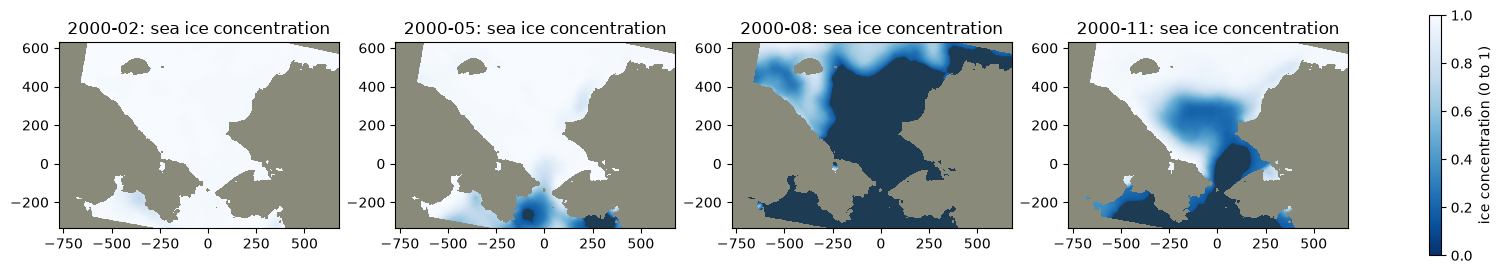

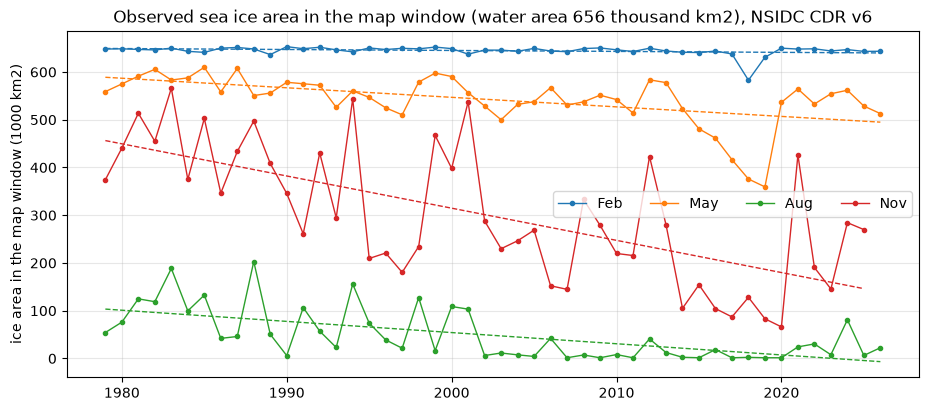

,month,years,trend_km2_per_decade,trend_start_km2,trend_end_km2,lowest,highest
0,Feb,1979 to 2026,-1995,649334,639958,2018 (582778),1990 (653132)
1,May,1979 to 2026,-19997,588960,494975,2019 (359377),1985 (609839)
2,Aug,1979 to 2026,-23420,103371,-6702,2011 (1380),1988 (202993)
3,Nov,1979 to 2025,-67419,456340,146211,2020 (66103),1983 (565962)


In [6]:
mx = np.linspace(L, R, nx) / 1000
my = np.linspace(T, B, ny) / 1000
fig, axes = plt.subplots(1, len(IMAGE_MONTHS), figsize=(5.2 * len(IMAGE_MONTHS), 3.9), squeeze=False)
for ax, m in zip(axes[0], IMAGE_MONTHS):
    c = grids.get((MAP_YEAR, m))
    ax.set_facecolor("#1d3b53")
    ax.contourf(mx, my, (~water).astype(float), levels=[0.5, 1.5], colors=["#8a8a7a"])
    if c is not None:
        im = ax.imshow(np.ma.masked_where(~(c >= EDGE), c), extent=[L / 1000, R / 1000, B / 1000, T / 1000], cmap="Blues_r", vmin=0, vmax=1)
    ax.set_title(f"{MAP_YEAR}-{m:02d}: sea ice concentration")
    ax.set_aspect("equal")
fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label="ice concentration (0 to 1)")
fig.savefig(FIG_DIR / f"06_ice_map_{MAP_YEAR}.png", dpi=130, bbox_inches="tight")
plt.show()

names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun", 7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
fig, ax = plt.subplots(figsize=(11, 4.5))
trend_rows = []
for m in IMAGE_MONTHS:
    d = table[(table.month == m)]
    line, = ax.plot(d.year, d.ice_area_km2 / 1000, "o-", markersize=3, linewidth=1, label=names[m])
    if len(d) > 5:
        p = np.polyfit(d.year, d.ice_area_km2, 1)
        ax.plot(d.year, np.polyval(p, d.year) / 1000, "--", color=line.get_color(), linewidth=1)
        first, last = int(d.year.min()), int(d.year.max())
        trend_rows.append({"month": names[m], "years": f"{first} to {last}", "trend_km2_per_decade": round(p[0] * 10), "trend_start_km2": round(np.polyval(p, first)), "trend_end_km2": round(np.polyval(p, last)), "lowest": f"{int(d.loc[d.ice_area_km2.idxmin(), 'year'])} ({round(d.ice_area_km2.min())})", "highest": f"{int(d.loc[d.ice_area_km2.idxmax(), 'year'])} ({round(d.ice_area_km2.max())})"})
ax.set_ylabel("ice area in the map window (1000 km2)")
ax.set_title(f"Observed sea ice area in the map window (water area {round(water_km2 / 1000)} thousand km2), NSIDC CDR v6")
ax.legend(ncol=4)
ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "06_ice_area_trends.png", dpi=130, bbox_inches="tight")
plt.show()
pd.DataFrame(trend_rows)

___
**END**